# Open-system TCL dynamics validation

This retains the two-cavity, two-emitter-per-cavity benchmark from `validate_open.py` in one consolidated validation module. Photon cutoff 2 is exact for the chosen two-excitation initial state. Photon loss is 0.1; emitter relaxation is either unequal (0.02,0.20) or equal (0.11,0.11); dephasing is absent.

The checks cover independently built operators, reduced versus full tensor-product evolution, trace/Hermiticity/positivity, Kraus completeness, analytic initial slopes, photon moments, singlet population, emitter imbalance, and timestep convergence. Channel averaging is deterministic, so these curves contain no Monte Carlo noise. Matrix exponentials implement ideal maps; they do not include gate synthesis errors.

In [1]:
from pathlib import Path
import os,sys,json,hashlib
os.environ.setdefault('MPLCONFIGDIR','/tmp/tcl-mpl')
os.environ.setdefault('NUMBA_CACHE_DIR','/tmp/tcl-numba')
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'resource_estimation/gqsp.py').is_file())
sys.path.insert(0,str(ROOT/'resource_estimation'))
sys.path.insert(0,str(ROOT/'validation'))
import numpy as np
import pandas as pd
from IPython.display import display,Image,Markdown
import gqsp as resources
import validation as validate


In [2]:
out=ROOT/'validation/results';path=out/'open_validation_summary.json'
RECOMPUTE=False
current=path.exists() and json.loads(path.read_text()).get('source_sha256')==hashlib.sha256(Path(validate.__file__).read_bytes()).hexdigest()
report=validate.run_open() if RECOMPUTE or not current else json.loads(path.read_text())
assert report['status']=='PASS'
display(pd.Series(report['parameters']))
display(pd.Series(report['checks']))


sampled          steps=  32 trace norm error=0.073927789


symmetric_split  steps=  32 trace norm error=0.00014579869


sampled          steps=  64 trace norm error=0.036751066


symmetric_split  steps=  64 trace norm error=3.6381437e-05


sampled          steps= 128 trace norm error=0.018318155


symmetric_split  steps= 128 trace norm error=9.091138e-06


... (5 outputs left out)

symmetric_split  steps=1024 trace norm error=1.4202743e-07


{
  "status": "PASS",
  "figure": "/Users/rakshit_gharat/Downloads/TCL_Lindblad_Qualtran_bundle_fixed/TCL_simulation_git/validation/results/open_validation.pdf",
  "sampled_order": 1.0005976128190734,
  "split_order": 2.0000105640095236
}


cavities                                                       2
emitters_per_cavity                                            2
photon_cutoff                                                  2
maximum_total_excitation                                       2
coupling_g                                                   1.0
hopping_t                                                    0.2
detuning                                                     0.0
polariton_potential                                          0.0
photon_loss                                                  0.1
unequal_relaxation_per_cavity                        [0.02, 0.2]
equal_relaxation_per_cavity                         [0.11, 0.11]
dephasing                                                    0.0
initial_state                    photons |0,0>; emitters |ee;gg>
final_time_in_inverse_g                                      4.0
dtype: object

exact_unequal                                            {'minimum_state_eigenvalue': -1.04095583872549...
exact_equal                                              {'minimum_state_eigenvalue': -6.09999774939638...
full_tensor_product_reference_frobenius_residual                                                       0.0
local_channels_vs_exact_dissipator_frobenius_residual                                                  0.0
dtype: object

,method,steps,dt,trace_norm_error,maximum_photon_error,maximum_factorial_error,maximum_photon_error_over_time,maximum_factorial_error_over_time,maximum_kraus_completeness_error,maximum_trace_error,maximum_hermiticity_error,minimum_state_eigenvalue
0,sampled,32,0.125000,7.392779e-02,2.093772e-02,6.022136e-04,2.253134e-02,2.170738e-02,3.291851e-16,2.886580e-15,4.075697e-16,-7.797275e-17
1,symmetric_split,32,0.125000,1.457987e-04,8.404541e-06,5.048699e-07,1.367452e-05,8.208925e-06,2.383953e-16,3.330669e-15,6.340807e-16,-4.434709e-16
2,sampled,64,0.062500,3.675107e-02,1.018085e-02,1.117083e-04,1.123930e-02,1.065110e-02,2.484438e-16,4.440892e-15,4.979044e-16,-3.705136e-17
3,symmetric_split,64,0.062500,3.638144e-05,2.120861e-06,1.230649e-07,3.416299e-06,2.085598e-06,2.366026e-16,8.881784e-15,2.734386e-15,-4.573768e-16
4,sampled,128,0.031250,1.831816e-02,5.013329e-03,1.245236e-04,5.588956e-03,5.291508e-03,2.236148e-16,3.996803e-15,1.037521e-15,-1.017987e-16
5,symmetric_split,128,0.031250,9.091138e-06,5.314353e-07,3.057074e-08,8.539306e-07,5.213502e-07,2.221474e-16,1.498801e-14,6.870932e-15,-1.507868e-15
6,sampled,256,0.015625,9.144268e-03,2.486785e-03,8.501881e-05,2.788420e-03,2.633872e-03,2.306721e-16,1.332268e-14,1.152214e-15,-1.158143e-16
7,symmetric_split,256,0.015625,2.272521e-06,1.329349e-07,7.630490e-09,2.134737e-07,1.303344e-07,2.221124e-16,6.106227e-15,5.011753e-15,-4.339158e-15
8,sampled,512,0.007812,4.568376e-03,1.238349e-03,4.819001e-05,1.392284e-03,1.313940e-03,2.250013e-16,5.662137e-15,2.187428e-15,-1.233889e-16
9,symmetric_split,512,0.007812,5.681139e-07,3.323842e-08,1.906822e-09,5.336782e-08,3.258339e-08,2.220522e-16,3.397282e-14,5.117467e-15,-3.258723e-15


,halving_ratios,last_pair_order
sampled,"[2.0115821410468855, 2.006264567600423, 2.0032...",1.000598
symmetric_split,"[4.007502110585074, 4.001857344398611, 4.00046...",2.000011


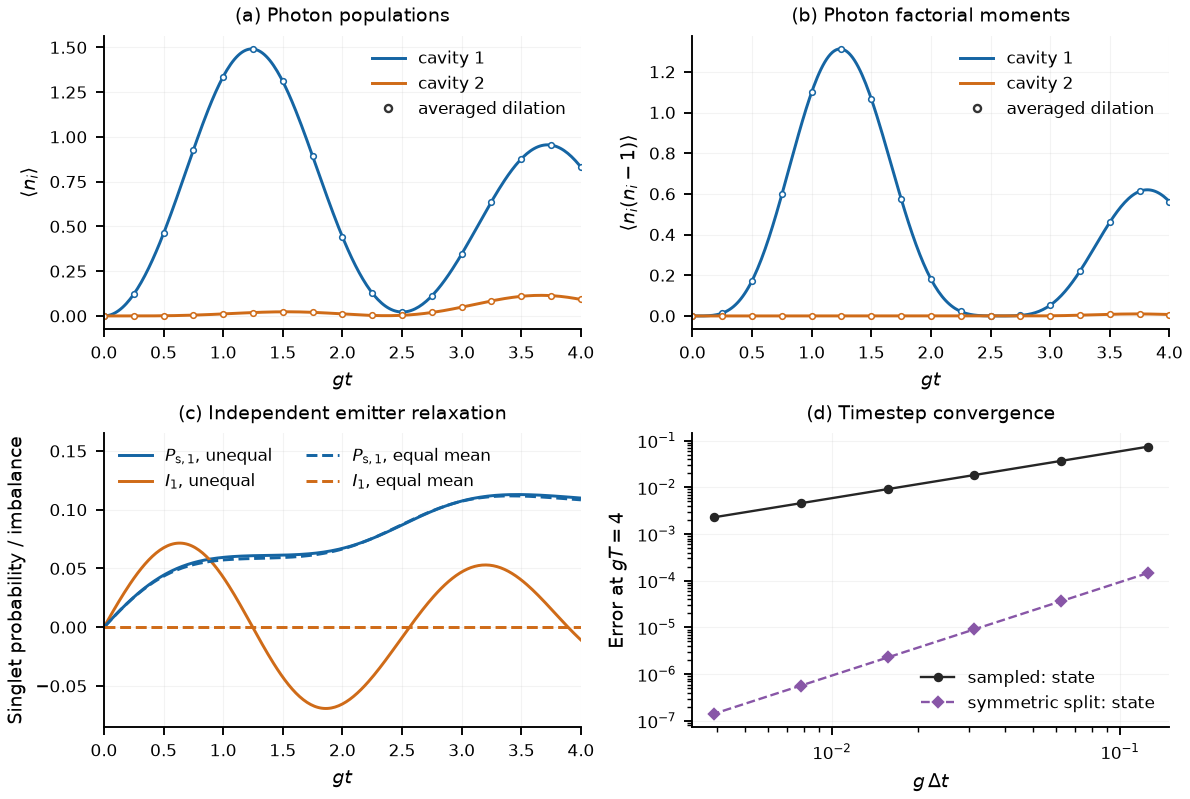

In [3]:
convergence=pd.read_csv(out/'open_convergence.csv')
display(convergence)
display(pd.DataFrame({m:r['trace_norm_error'] for m,r in report['observed_orders'].items()}).T)
display(Image(filename=str(out/'open_validation_preview.png')))


The sampled averaged dilation converges at first order; the exact local-channel symmetric split converges at second order. Equal independent emitter relaxation still populates singlets, while the emitter imbalance stays zero. The physical benchmark does not certify a diamond-norm bound for all inputs or a large-lattice quantum resource estimate. Appendix H's resource circuit is tested separately, including the dephasing branch absent from these dynamics.

In [4]:
gate_record=json.loads((out/'gate_validation.json').read_text())
assert gate_record['validation_sha256']==hashlib.sha256(Path(validate.__file__).read_bytes()).hexdigest()
assert gate_record['resources_sha256']==resources.source_hashes()
print(gate_record['pytest_output'])


........................                                                 [100%]
24 passed in 341.25s (0:05:41)
